# Pemetaan dan Klasifikasi Tutupan Lahan (Sawah & Pemukiman/Bukan Sawah) Berbasis Citra Satelit Sentinel-2A dan Machine Learning Random Forest

Dokumentasi ini menyajikan metodologi dan implementasi komputasi komprehensif untuk klasifikasi tutupan lahan secara kuantitatif. Analisis ini memanfaatkan data penginderaan jauh optik multispektral **Sentinel-2A (Level-2A / Bottom-of-Atmosphere Reflectance)** yang diakses dan diolah secara terpadu melalui platform komputasi awan **openEO (Copernicus Data Space Ecosystem)**.

Alur pemrosesan dirancang secara metodologis mulai dari integrasi data spasial vektor **GeoJSON**, pembagian dataset terstratifikasi pada tingkat poligon sampel (*Group-based Stratified Partition*) guna mencegah kebocoran data (*spatial data leakage*), ekstraksi fitur multispektral serta indeks bio-fisik vegetasi, air, dan bangunan (**NDVI, NDWI, NDBI**), pemodelan klasifikasi menggunakan algoritma *ensemble* **Random Forest Classifier**, validasi performa statistik independen, hingga perwujudan kartografi dalam format peta 2D dan model elevasi digital 3D interaktif.

---

### 🗺️ Kerangka Kerja Alur Analisis (End-to-End Workflow)

| Tahapan | Uraian Aktivitas Teknis | Format & Berkas Luaran |
| :---: | :--- | :--- |
| **1** | **Persiapan Data Spasial & Partisi Sampel** | Membaca berkas vektor GeoJSON, standardisasi kelas, pembuatan ID unik poligon, dan partisi terstratifikasi (*70% Train / 30% Test*) berbasis poligon. | `pembagian_dataset_train_test.csv`, `data_training_poligon.csv`, `data_testing_poligon.csv` |
| **2** | **Akuisisi Citra Sentinel-2A via openEO** | Mengunduh citra satelit BOA bebas awan menggunakan penyaringan *Scene Classification Layer* (SCL) dan komposit temporal *median* sepanjang rentang waktu satu tahun. | `sentinel2_area_studi.tif` (GeoTIFF multi-band) |
| **3** | **Ekstraksi Fitur Spektral & Indeks Bio-Fisik** | Ekstraksi nilai piksel dari poligon menggunakan masking spasial, konversi ke reflektansi permukaan, dan penghitungan indeks NDVI, NDWI, serta NDBI. | `fitur_sampel.csv`, `fitur_piksel_training.csv`, `fitur_piksel_testing.csv` |
| **4** | **Pelatihan Model & Evaluasi Klasifikasi** | Pelatihan model Random Forest pada data piksel latih murni dan pengujian independen pada data uji yang tidak pernah dilihat model saat pelatihan. | Metrik Akurasi, Cohen's Kappa ($\kappa$), Confusion Matrix, Classification Report, & Feature Importance |
| **5** | **Inferensi Spasial Menyeluruh** | Klasifikasi seluruh area kajian secara piksel demi piksel untuk menghasilkan peta tutupan lahan georeferensi. | `klasifikasi_sawah_pemukiman.tif` |
| **6** | **Visualisasi Kartografi 2D & Topografi 3D** | Pembuatan peta tematik 2D statis dan visualisasi 3D interaktif (*terrain draping*) di atas relief Digital Elevation Model (DEM). | `peta_klasifikasi.png` & `peta_3d.html` |


## 1. Data Masukan, Partisi Sampel Bebas Kebocoran Data (Data Leakage), & Akuisisi Satelit openEO

### 1.1 Struktur dan Karakteristik Data Masukan Geospasial
Data spasial yang digunakan bersumber dari berkas vektor GeoJSON (`data/geojson/lamongan.geojson` / `input2.geojson`). Data ini memuat 101 entitas geometri poligon yang terbagi menjadi:
1. **Batas Administrasi / Wilayah Kajian (`Wilayah`/`Daerah` - 1 Poligon):** Digunakan secara eksklusif sebagai *bounding box* dan batas pemotongan spasial (*spatial extent*) saat mengunduh citra satelit, **bukan** sebagai sampel pelatihan.
2. **Sampel Poligon Sawah (`Sawah` - 50 Poligon):** Representasi lahan pertanian sawah dengan berbagai fase pertumbuhan (penggenangan, vegetatif, generatif).
3. **Sampel Poligon Pemukiman/Bukan Sawah (`Bukan Sawah`/`Pemukiman` - 50 Poligon):** Representasi kawasan terbangun, perumahan, infrastruktur, tanah terbuka, dan tutupan non-sawah lainnya.

Setiap poligon sampel diberikan identifikasi unik (`sawah_01` s.d. `sawah_50` dan `bukan_sawah_01` s.d. `bukan_sawah_50`) untuk melacak asal-usul spasial piksel secara transparan.

---

### 1.2 Prinsip Partisi Dataset: Pencegahan Kebocoran Data Spasial (*Spatial Data Leakage*)
Dalam analisis geospasial berbasis citra penginderaan jauh, piksel-piksel yang berada di dalam satu poligon yang sama memiliki **autokorelasi spasial yang sangat tinggi** (sesuai *Tobler's First Law of Geography*). 

> **⚠️ Catatan Metodologis Kritis:** Jika pembagian data latih (*training*) dan uji (*testing*) dilakukan secara acak pada tingkat piksel (*pixel-level random split*), piksel dari poligon yang sama akan terdistribusi ke dalam kedua set. Hal ini menyebabkan **kebocoran data (*spatial data leakage*)** dan menghasilkan akurasi semu (*optimistic evaluation bias*) karena model hanya "menghafal" karakteristik poligon yang sudah dikenali saat latihan.

Untuk menjamin pengujian yang valid dan objektif:
- Pembagian data dilakukan secara ketat pada **tingkat poligon sampel (*Group-based Stratified Split*)**.
- Proporsi partisi ditetapkan sebesar **70% Data Latih (Training)** dan **30% Data Uji (Testing)**:
  - **Set Pelatihan (70%):** 35 Poligon Sawah + 35 Poligon Bukan Sawah (**Total 70 Poligon Sampel**).
  - **Set Pengujian (30%):** 15 Poligon Sawah + 15 Poligon Bukan Sawah (**Total 30 Poligon Sampel Independen**).

---

### 1.3 Struktur Berkas Tabular Partisi Dataset (`data/csv/split_dataset/`)
Untuk kemudahan audit dan validasi saintifik, luaran partisi dataset diekspor ke dalam beberapa berkas CSV terstruktur:
* **Tingkat Entitas Poligon (Area Sampel):**
  - `data/csv/pembagian_dataset_train_test.csv`: Rekapitulasi status split seluruh 100 poligon sampel.
  - `data/csv/split_dataset/data_training_poligon.csv`: Daftar 70 ID poligon yang dialokasikan sebagai data latih.
  - `data/csv/split_dataset/data_testing_poligon.csv`: Daftar 30 ID poligon yang dialokasikan sebagai data uji independen.
* **Tingkat Entitas Piksel (Titik Data Fitur Spektral):**
  - `data/csv/split_dataset/fitur_piksel_training.csv`: Seluruh baris data piksel hasil ekstraksi dari 70 poligon latih yang digunakan sebagai masukan algoritma *machine learning*.
  - `data/csv/split_dataset/fitur_piksel_testing.csv`: Seluruh baris data piksel dari 30 poligon uji yang **hanya digunakan pada tahap pengujian akhir model**.

---

### 1.4 Protokol Akuisisi Citra Sentinel-2A via openEO
Pengunduhan citra satelit dilakukan melalui API **openEO** yang terhubung langsung ke **Copernicus Data Space Ecosystem**. Pemrosesan data mentah dilakukan secara terdistribusi di sisi server (*cloud-side processing*):
- **Koleksi Citra:** `SENTINEL2_L2A` (reflektansi permukaan terrektifikasi atmosfer / *Bottom-of-Atmosphere*).
- **Saluran Spektral:** Saluran esensial optik (B02, B03, B04, B08, B11) dan lapisan klasifikasi pemandangan (*Scene Classification Layer* - SCL).
- **Kompensasi Awan & Reduksi Temporal:**
  1. *Filter Scene-Level*: Batas tutupan awan maksimum ditentukan 30% (`max_cloud_cover = 30`).
  2. *Pixel-Level SCL Masking*: Piksel dengan klasifikasi awan tebal, awan tipis (*cirrus*), bayangan awan, dan salju/es dihilangkan secara otomatis sebelum perhitungan statistik.
  3. *Median Reducer*: Menggabungkan seluruh akuisisi dalam rentang waktu 1 tahun menggunakan operator nilai tengah (*median*) untuk menghasilkan satu citra komposit bebas awan (*cloud-free composite raster*).


In [1]:
import openeo, json, os
import geopandas as gpd
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Read GeoJSON Dataset
gdf = gpd.read_file("../data/geojson/lamongan.geojson")

# Standardisasi nama kolom & nilai (lowercase)
type_col = "type" if "type" in gdf.columns else "Type"
gdf["type_clean"] = gdf[type_col].astype(str).str.lower().str.strip()

print("=== TOTAL POLIGON MASUKAN GEOJSON ===")
print(gdf["type_clean"].value_counts())

# Ambil Poligon Sawah dan Pemukiman / Bukan Sawah
samples = gdf[gdf["type_clean"].isin(["sawah", "pemukiman", "bukan sawah"])].copy().reset_index(drop=True)

# Berikan ID Poligon Unik
sawah_cnt, bukan_sawah_cnt = 1, 1
id_poligon = []
for t in samples["type_clean"]:
    if t == "sawah":
        id_poligon.append(f"sawah_{sawah_cnt:02d}")
        sawah_cnt += 1
    else:
        id_poligon.append(f"bukan_sawah_{bukan_sawah_cnt:02d}")
        bukan_sawah_cnt += 1
samples["ID_Poligon"] = id_poligon
samples["Type"] = samples["type_clean"]

# Pembagian Stratified Train-Test (70% Training, 30% Testing)
train_ids, test_ids = train_test_split(
    samples["ID_Poligon"],
    test_size=0.30,
    stratify=samples["Type"],
    random_state=42
)
samples["Status_Split"] = np.where(samples["ID_Poligon"].isin(train_ids), "Training", "Testing")

# Ekspor CSV
split_dir = "../data/csv/split_dataset"
os.makedirs(split_dir, exist_ok=True)
samples[["ID_Poligon", "Type", "Status_Split"]].to_csv("../data/csv/pembagian_dataset_train_test.csv", index=False)
samples[samples["Status_Split"] == "Training"][["ID_Poligon", "Type"]].to_csv(os.path.join(split_dir, "data_training_poligon.csv"), index=False)
samples[samples["Status_Split"] == "Testing"][["ID_Poligon", "Type"]].to_csv(os.path.join(split_dir, "data_testing_poligon.csv"), index=False)

print("\n=== RINGKASAN PEMBAGIAN DATASET POLIGON (TRAINING vs TESTING) ===")
print(pd.crosstab(samples["Type"], samples["Status_Split"], margins=True))
print(f"\n[SUCCESS]: File CSV Poligon Latih & Uji disimpan di '{split_dir}/'")

# 2. Unduh Citra Satelit Sentinel-2A via openEO
tif_target = "../data/tif/sentinel2_area_studi.tif"
if os.path.exists(tif_target):
    print(f"\n[INFO]: File raster lokal '{tif_target}' sudah tersedia.")
else:
    try:
        # Cari geometri poligon batas wilayah (wilayah / daerah)
        daerah_df = gdf[gdf["type_clean"].isin(["wilayah", "daerah", "batas daerah", "boundary"])]
        if len(daerah_df) > 0:
            daerah = daerah_df.geometry.iloc[0]
        else:
            # Fallback: gunakan bounding box gabungan seluruh sampel
            daerah = gdf.unary_union.envelope
            
        geom = json.loads(gpd.GeoSeries([daerah]).to_json())["features"][0]["geometry"]
        
        conn = openeo.connect("openeo.dataspace.copernicus.eu").authenticate_oidc()
        bands = ["B02", "B03", "B04", "B08", "B11", "SCL"]
        cube = conn.load_collection(
            "SENTINEL2_L2A",
            spatial_extent=geom,
            temporal_extent=["2025-08-24", "2026-08-23"],
            bands=bands,
            max_cloud_cover=30,
        )
        scl = cube.band("SCL")
        mask = (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10) | (scl == 11)
        cube = cube.mask(mask.resample_cube_spatial(cube)).filter_bands(bands[:-1])
        cube = cube.reduce_dimension(dimension="t", reducer="median")
        
        os.makedirs("../data/tif", exist_ok=True)
        cube.download(tif_target, format="GTiff")
        print("\nSUCCESS: Berhasil mengunduh citra Sentinel-2A via openEO.")
    except Exception as e:
        print(f"\n[openEO Info]: {e}")


=== TOTAL POLIGON MASUKAN GEOJSON ===
type_clean
sawah          50
bukan sawah    50
wilayah         1
Name: count, dtype: int64

=== RINGKASAN PEMBAGIAN DATASET POLIGON (TRAINING vs TESTING) ===
Status_Split  Testing  Training  All
Type                                
bukan sawah        15        35   50
sawah              15        35   50
All                30        70  100

[SUCCESS]: File CSV Poligon Latih & Uji disimpan di '../data/csv/split_dataset/'

[INFO]: File raster lokal '../data/tif/sentinel2_area_studi.tif' sudah tersedia.


## 2. Ekstraksi Fitur Spektral Multispektral dan Formulasi Indeks Bio-Fisik Lahan

### 2.1 Saluran Spektral Sentinel-2A yang Digunakan
Citra satelit Sentinel-2A menyediakan resolusi spasial tinggi (10–20 meter). Nilai digital (*Digital Number* / DN) pada berkas GeoTIFF dikalibrasi ke dalam satuan reflektansi permukaan murni (*Bottom-of-Atmosphere Reflectance*) dengan faktor skala $1/10.000$:

$$\text{Reflektansi Permukaan} = \frac{\text{DN}}{10.000}$$

| Saluran (*Band*) | Panjang Gelombang Pusat | Resolusi Spasial | Karakteristik & Kegunaan Utama |
| :--- | :---: | :---: | :--- |
| **B02 - Blue** | 490 nm | 10 m | Sensitif terhadap hamburan atmosfer, pantulan badan air, dan material bangunan cerah. |
| **B03 - Green** | 560 nm | 10 m | Menangkap puncak pantulan vegetasi hijau sehat dan digunakan pada indeks air. |
| **B04 - Red** | 665 nm | 10 m | Wilayah penyerapan energi utama oleh klorofil daun pada tanaman aktif. |
| **B08 - NIR (Near-Infrared)** | 842 nm | 10 m | Pantulan sangat tinggi dari struktur sel mesofil daun vegetasi sehat. |
| **B11 - SWIR-1 (Shortwave Infrared)** | 1610 nm | 20 m | Sangat sensitif terhadap kandungan kelembapan tanah, kadar air kanopi, serta material atap/beton perkotaan. |

---

### 2.2 Formulasi Matematika Indeks Spektral Bio-Fisik
Untuk mempertegas kontras spektral antara vegetasi sawah dan kawasan terbangun pemukiman, dihitung 3 indeks transformasi spektral:

1. **Normalized Difference Vegetation Index (NDVI)**  
   Digunakan untuk mengukur kerapatan biomassa, keaktifan fotosintesis, dan kehijauan vegetasi:
   $$\text{NDVI} = \frac{\text{B08} - \text{B04}}{\text{B08} + \text{B04}}$$

2. **Normalized Difference Water Index (NDWI)**  
   Sensitif terhadap kandungan kelembapan permukaan tanah dan fase penggenangan air (*flooding stage*) pada area persawahan:
   $$\text{NDWI} = \frac{\text{B03} - \text{B08}}{\text{B03} + \text{B08}}$$

3. **Normalized Difference Built-up Index (NDBI)**  
   Memaksimalkan respons pantulan gelombang pendek inframerah dari permukaan kedap air (*impervious surface*), bangunan fisik, dan tanah kering:
   $$\text{NDBI} = \frac{\text{B11} - \text{B08}}{\text{B11} + \text{B08}}$$

---

### 2.3 Mekanisme Ekstraksi Spasial dengan `rasterio.mask`
Proses ekstraksi dilakukan per entitas poligon menggunakan fungsi `rasterio.mask.mask` dengan konfigurasi `all_touched=True`. Hal ini menjamin seluruh piksel yang bersentuhan dengan batas poligon tetap terekstraksi. Piksel dengan nilai tak valid (*NoData* atau *NaN*) secara otomatis dibersihkan sebelum diagregasi dan disimpan ke berkas CSV.


In [2]:
import os, rasterio, numpy as np, pandas as pd
from rasterio.mask import mask as rio_mask

tif_path = "../data/tif/sentinel2_area_studi.tif"
split_dir = "../data/csv/split_dataset"

if os.path.exists(tif_path):
    with rasterio.open(tif_path) as src:
        smp = samples.to_crs(src.crs)
        rows = []
        pix_tr_rows, pix_te_rows = [], []
        
        for idx, r in smp.iterrows():
            try:
                m, _ = rio_mask(src, [r.geometry], crop=True, all_touched=True, filled=False)
            except ValueError:
                continue
            arr = m.astype("float32").filled(np.nan) / 10000
            if src.nodata is not None:
                arr[m.data == src.nodata] = np.nan
            b02, b03, b04, b08, b11 = [arr[k].ravel() for k in range(5)]
            ok = ~np.isnan(b04) & ~np.isnan(b08) & ~np.isnan(b03) & ~np.isnan(b11) & (b04 > 0) & (b08 > 0)
            if ok.sum() == 0:
                continue
            b02_v, b03_v, b04_v, b08_v, b11_v = b02[ok], b03[ok], b04[ok], b08[ok], b11[ok]
            ndvi = (b08_v - b04_v) / (b08_v + b04_v + 1e-6)
            ndwi = (b03_v - b08_v) / (b03_v + b08_v + 1e-6)
            ndbi = (b11_v - b08_v) / (b11_v + b08_v + 1e-6)
            
            rows.append({
                "ID_Poligon": r["ID_Poligon"],
                "Kelas": r["Type"],
                "Status_Split": r["Status_Split"],
                "n_piksel": int(ok.sum()),
                "B02": b02_v.mean(), "B03": b03_v.mean(), "B04": b04_v.mean(),
                "B08": b08_v.mean(), "B11": b11_v.mean(),
                "NDVI": ndvi.mean(), "NDWI": ndwi.mean(), "NDBI": ndbi.mean()
            })
            
            for i in range(len(b02_v)):
                p_row = {
                    "ID_Poligon": r["ID_Poligon"],
                    "Kelas": r["Type"],
                    "B02": round(b02_v[i], 4), "B03": round(b03_v[i], 4), "B04": round(b04_v[i], 4),
                    "B08": round(b08_v[i], 4), "B11": round(b11_v[i], 4),
                    "NDVI": round(ndvi[i], 4), "NDWI": round(ndwi[i], 4), "NDBI": round(ndbi[i], 4)
                }
                if r["Status_Split"] == "Training":
                    pix_tr_rows.append(p_row)
                else:
                    pix_te_rows.append(p_row)
                    
    df_fitur = pd.DataFrame(rows)
    df_pix_tr = pd.DataFrame(pix_tr_rows)
    df_pix_te = pd.DataFrame(pix_te_rows)
    
    print(f"Total Sampel Poligon Valid: {len(df_fitur)}")
    print(f"- Jumlah Piksel Latih (fitur_piksel_training.csv) : {len(df_pix_tr)} baris (dari 70 Poligon Latih)")
    print(f"- Jumlah Piksel Uji   (fitur_piksel_testing.csv)  : {len(df_pix_te)} baris (dari 30 Poligon Uji)")
    print("\n=== RATA-RATA INDEKS SPEKTRAL PER KELAS & SPLIT STATUS ===")
    print(df_fitur.groupby(["Kelas", "Status_Split"])[["n_piksel", "NDVI", "NDWI", "NDBI"]].mean())
    
    os.makedirs("../data/csv", exist_ok=True)
    os.makedirs(split_dir, exist_ok=True)
    df_fitur.to_csv("../data/csv/fitur_sampel.csv", index=False)
    df_pix_tr.to_csv(os.path.join(split_dir, "fitur_piksel_training.csv"), index=False)
    df_pix_te.to_csv(os.path.join(split_dir, "fitur_piksel_testing.csv"), index=False)
    print(f"\n[SUCCESS]: File CSV 'fitur_piksel_training.csv' ({len(df_pix_tr)} baris) & 'fitur_piksel_testing.csv' ({len(df_pix_te)} baris) berhasil diekspor ke '{split_dir}/'")

Total Sampel Poligon Valid: 100
- Jumlah Piksel Latih (fitur_piksel_training.csv) : 6499 baris (dari 70 Poligon Latih)
- Jumlah Piksel Uji   (fitur_piksel_testing.csv)  : 3092 baris (dari 30 Poligon Uji)

=== RATA-RATA INDEKS SPEKTRAL PER KELAS & SPLIT STATUS ===
                            n_piksel      NDVI      NDWI      NDBI
Kelas       Status_Split                                          
bukan sawah Testing        15.133333  0.203878 -0.290447  0.140918
            Training       13.914286  0.183158 -0.275524  0.148802
sawah       Testing       191.000000  0.604453 -0.522887 -0.238457
            Training      171.771429  0.613199 -0.526602 -0.259423

[SUCCESS]: File CSV 'fitur_piksel_training.csv' (6499 baris) & 'fitur_piksel_testing.csv' (3092 baris) berhasil diekspor ke '../data/csv/split_dataset/'


## 3. Pemodelan Klasifikasi Random Forest, Evaluasi Metrik, dan Inferensi Spasial

### 3.1 Konsep Algoritma Random Forest Classifier
**Random Forest** merupakan algoritma pembelajaran mesin berbasis *ensemble decision trees* yang memanfaatkan teknik *Bootstrap Aggregating (Bagging)* dan seleksi fitur acak (*Random Subspace*). Algoritma ini memiliki keunggulan performa yang sangat tinggi, resisten terhadap *overfitting*, serta mampu menangani data multivariat non-linear dengan interaksi spektral yang kompleks.

**Konfigurasi Hiperparameter Model:**
- `n_estimators = 300`: Membangun 300 pohon keputusan independen untuk menjamin stabilitas varians dan konvergensi prediksi.
- `class_weight = "balanced"`: Memberikan pembobotan dinamis berbanding terbalik dengan frekuensi kemunculan kelas guna mengatasi disparitas jumlah piksel sampel antar kelas.
- `random_state = 42`: Memastikan eksperimen dapat direplikasi secara konsisten (*reproducibility*).
- `n_jobs = -1`: Memanfaatkan seluruh inti prosesor (*multi-threading*) untuk akselerasi komputasi.

---

### 3.2 Strategi Validasi Ketat Tanpa Bias
Proses validasi dilakukan secara independen terhadap kumpulan data uji yang berasal dari 30 poligon pengujian (15 poligon Sawah dan 15 poligon Bukan Sawah/Pemukiman). Model dilatih secara eksklusif menggunakan matriks data latih $\mathbf{X}_{\text{train}}$ dan label target $\mathbf{y}_{\text{train}}$, kemudian dievaluasi menggunakan metrik statistik standar:
- **Akurasi Keseluruhan (*Overall Accuracy*)**: Persentase total piksel yang terklasifikasi secara tepat.
- **Koefisien Cohen's Kappa ($\kappa$)**: Mengukur tingkat kesesuaian antara prediksi dan kenyataan dengan mengeliminasi faktor kebetulan acak (*chance agreement*):
  $$\kappa = \frac{P_o - P_e}{1 - P_e}$$
- **Precision, Recall, dan F1-Score**: Evaluasi sensitivitas deteksi per kategori tutupan lahan.
- **Tingkat Kepentingan Fitur (*Feature Importance / Mean Decrease in Impurity*)**: Analisis kontribusi masing-masing saluran spektral dan indeks bio-fisik dalam membentuk pohon keputusan.

---

### 3.3 Generasi Raster Peta Klasifikasi (`klasifikasi_sawah_pemukiman.tif`)
Setelah model selesai dievaluasi, model Random Forest diaplikasikan pada seluruh piksel citra satelit area studi untuk menghasilkan peta tutupan lahan digital bertipe GeoTIFF dengan skema klasifikasi:
- Nilai `0`: *NoData* / Area di luar batas studi.
- Nilai `1`: **Sawah** (Lahan pertanian basah).
- Nilai `2`: **Bukan Sawah / Pemukiman** (Lahan terbangun, infrastruktur, tanah terbuka, dll).


In [3]:
import os, rasterio, numpy as np, pandas as pd
from rasterio.mask import mask as rio_mask
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score, classification_report

TIF = "../data/tif/sentinel2_area_studi.tif"
NAMA_FITUR = ["B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI", "NDBI"]

if os.path.exists(TIF):
    X_tr_list, y_tr_list = [], []
    X_te_list, y_te_list = [], []
    
    with rasterio.open(TIF) as src:
        smp = samples.to_crs(src.crs)
        for idx, r in smp.iterrows():
            try:
                m, _ = rio_mask(src, [r.geometry], crop=True, all_touched=True, filled=False)
            except ValueError:
                continue
            arr = m.astype("float32").filled(np.nan) / 10000
            if src.nodata is not None:
                arr[m.data == src.nodata] = np.nan
            b02, b03, b04, b08, b11 = [arr[k].ravel() for k in range(5)]
            ok = ~np.isnan(b04) & ~np.isnan(b08) & ~np.isnan(b03) & ~np.isnan(b11) & (b04 > 0) & (b08 > 0)
            if ok.sum() == 0:
                continue
            b02_v, b03_v, b04_v, b08_v, b11_v = b02[ok], b03[ok], b04[ok], b08[ok], b11[ok]
            ndvi = (b08_v - b04_v) / (b08_v + b04_v + 1e-6)
            ndwi = (b03_v - b08_v) / (b03_v + b08_v + 1e-6)
            ndbi = (b11_v - b08_v) / (b11_v + b08_v + 1e-6)
            
            feats = np.column_stack([b02_v, b03_v, b04_v, b08_v, b11_v, ndvi, ndwi, ndbi])
            if r["Status_Split"] == "Training":
                X_tr_list.append(feats)
                y_tr_list += [r["Type"]] * len(feats)
            else:
                X_te_list.append(feats)
                y_te_list += [r["Type"]] * len(feats)

    X_train, y_train = np.vstack(X_tr_list), np.array(y_tr_list)
    X_test, y_test = np.vstack(X_te_list), np.array(y_te_list)

    print(f"=== EKSTRAKSI PIKSEL TRAIN vs TEST ===")
    print(f"Jumlah Piksel Training : {len(y_train)} piksel (dari {len(train_ids)} poligon)")
    print(f"Jumlah Piksel Testing  : {len(y_test)} piksel (dari {len(test_ids)} poligon)")
    
    # Melatih Model Random Forest
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)

    # Prediksi Data Training & Testing
    pred_train = rf.predict(X_train)
    pred_test = rf.predict(X_test)

    # Deteksi label secara dinamis dari data
    labels = sorted(list(set(y_train) | set(y_test)))
    
    print("\n=== EVALUASI PERFORMA MODEL ===")
    print(f"Akurasi Data Training : {accuracy_score(y_train, pred_train) * 100:.2f}%")
    print(f"Akurasi Data Testing  : {accuracy_score(y_test, pred_test) * 100:.2f}%")
    print(f"Cohen's Kappa (Test)  : {cohen_kappa_score(y_test, pred_test):.4f}")
    
    print("\n=== CONFUSION MATRIX (DATA TESTING) ===")
    cm_df = pd.DataFrame(
        confusion_matrix(y_test, pred_test, labels=labels),
        index=[f"Aktual_{l}" for l in labels],
        columns=[f"Prediksi_{l}" for l in labels]
    )
    print(cm_df)

    print("\n=== CLASSIFICATION REPORT (DATA TESTING) ===")
    print(classification_report(y_test, pred_test))

    print("\n=== FEATURE IMPORTANCES ===")
    for n, v in sorted(zip(NAMA_FITUR, rf.feature_importances_), key=lambda t: -t[1]):
        print(f"{n:5s} : {v:.3f}")

    # Menghasilkan & Menyimpan Citra Raster Hasil Klasifikasi
    with rasterio.open(TIF) as src:
        img = src.read().astype("float32") / 10000
        b02, b03, b04, b08, b11 = img[:5]
        ndvi = (b08 - b04) / (b08 + b04 + 1e-6)
        ndwi = (b03 - b08) / (b03 + b08 + 1e-6)
        ndbi = (b11 - b08) / (b11 + b08 + 1e-6)
        
        h, w = b02.shape
        stacked = np.stack([b02, b03, b04, b08, b11, ndvi, ndwi, ndbi], axis=-1).reshape(-1, 8)
        valid_mask = ~np.isnan(stacked).any(axis=1) & (stacked[:, 3] > 0)
        
        pred_map = np.zeros(h * w, dtype=np.uint8)
        if valid_mask.any():
            pred_labels = rf.predict(stacked[valid_mask])
            # 1 = Sawah, 2 = Bukan Sawah
            is_sawah = np.char.lower(pred_labels.astype(str)) == "sawah"
            pred_map[valid_mask] = np.where(is_sawah, 1, 2)
        
        pred_map = pred_map.reshape(h, w)
        meta = src.meta.copy()
        meta.update({"count": 1, "dtype": "uint8", "nodata": 0})
        out_tif = "../data/tif/klasifikasi_sawah_pemukiman.tif"
        with rasterio.open(out_tif, "w", **meta) as dst:
            dst.write(pred_map, 1)
        print(f"\nSUCCESS: Raster hasil klasifikasi disimpan di '{out_tif}'")


=== EKSTRAKSI PIKSEL TRAIN vs TEST ===
Jumlah Piksel Training : 6499 piksel (dari 70 poligon)
Jumlah Piksel Testing  : 3092 piksel (dari 30 poligon)

=== EVALUASI PERFORMA MODEL ===
Akurasi Data Training : 100.00%
Akurasi Data Testing  : 97.77%
Cohen's Kappa (Test)  : 0.8433

=== CONFUSION MATRIX (DATA TESTING) ===
                    Prediksi_bukan sawah  Prediksi_sawah
Aktual_bukan sawah                   204              23
Aktual_sawah                          46            2819

=== CLASSIFICATION REPORT (DATA TESTING) ===
              precision    recall  f1-score   support

 bukan sawah       0.82      0.90      0.86       227
       sawah       0.99      0.98      0.99      2865

    accuracy                           0.98      3092
   macro avg       0.90      0.94      0.92      3092
weighted avg       0.98      0.98      0.98      3092


=== FEATURE IMPORTANCES ===
NDBI  : 0.265
B11   : 0.217
NDVI  : 0.210
B04   : 0.145
B02   : 0.078
NDWI  : 0.046
B03   : 0.031
B08   : 0.00

## 4. Visualisasi Kartografi 2D, Pemodelan Permukaan 3D Interaktif, dan Rekapitulasi Berkas

### 4.1 Visualisasi Kartografi 2D (Peta Tematik Klasifikasi)
Peta klasifikasi tutupan lahan disajikan dalam bentuk plot tematik 2D resolusi tinggi dengan kode warna terstandarisasi:
- **Hijau (#27ae60):** Kelas Sawah
- **Oranye (#d35400):** Kelas Bukan Sawah / Pemukiman

Peta ini dilengkapi dengan informasi statistik luas cakupan piksel serta persentase proporsi masing-masing kelas di seluruh wilayah studi.

---

### 4.2 Pemodelan Topografi 3D Interaktif (*Terrain Draping*)
Peta tutupan lahan hasil klasifikasi ditumpangsusunkan secara spasial (*draped*) di atas data model elevasi digital **Copernicus DEM (Digital Elevation Model 30m)** menggunakan pustaka **Plotly Surface**. Visualisasi ini memberikan pemahaman mendalam mengenai pola distribusi spasial lahan sawah (yang umumnya terkonsentrasi di dataran rendah bertopografi datar) terhadap pemukiman dan relief topografi sekitar. 

Visualisasi ini diekspor ke dalam format berkas **`assets/editor/html/peta_3d.html`**, sehingga pengguna dapat berinteraksi secara dinamis (memutar sudut pandang 3D, memperbesar/zoom, dan menggeser/pan) langsung di peramban web tanpa memerlukan perangkat lunak GIS khusus.

---

### 4.3 Rekapitulasi Berkas Luaran dan Struktur Proyek

| Kategori Data | Nama Berkas / Direktori | Deskripsi dan Peran Data |
| :--- | :--- | :--- |
| **Vektor Spasial** | `data/geojson/lamongan.geojson` | Data vektor 101 poligon (batas administrasi dan sampel tutupan lahan). |
| **Tabular Partisi** | `data/csv/pembagian_dataset_train_test.csv` | Rekapitulasi 100 poligon sampel dan status partisi (*Training* vs *Testing*). |
| | `data/csv/split_dataset/data_training_poligon.csv` | Daftar 70 ID poligon sampel yang dialokasikan sebagai data latih. |
| | `data/csv/split_dataset/data_testing_poligon.csv` | Daftar 30 ID poligon sampel yang dialokasikan sebagai data uji independen. |
| **Tabular Fitur** | `data/csv/fitur_sampel.csv` | Rata-rata nilai spektral dan indeks bio-fisik per poligon sampel. |
| | `data/csv/split_dataset/fitur_piksel_training.csv` | Matriks fitur spektral seluruh piksel data latih (**digunakan melatih model**). |
| | `data/csv/split_dataset/fitur_piksel_testing.csv` | Matriks fitur spektral seluruh piksel data uji (**digunakan murni untuk validasi**). |
| **Raster GeoTIFF** | `data/tif/sentinel2_area_studi.tif` | Citra satelit komposit Sentinel-2A 5 band (B02, B03, B04, B08, B11) terkoreksi atmosfer. |
| | `data/tif/klasifikasi_sawah_pemukiman.tif` | Peta raster hasil prediksi tutupan lahan (`1 = Sawah`, `2 = Bukan Sawah`). |
| | `data/tif/dem_area_studi.tif` | Raster Digital Elevation Model (DEM) wilayah studi. |
| **Visualisasi & Web** | `assets/editor/html/peta_3d.html` | Model visualisasi 3D permukaan interaktif berbasis Plotly WebGL. |


=== VISUALISASI PETA KLASIFIKASI 2D ===


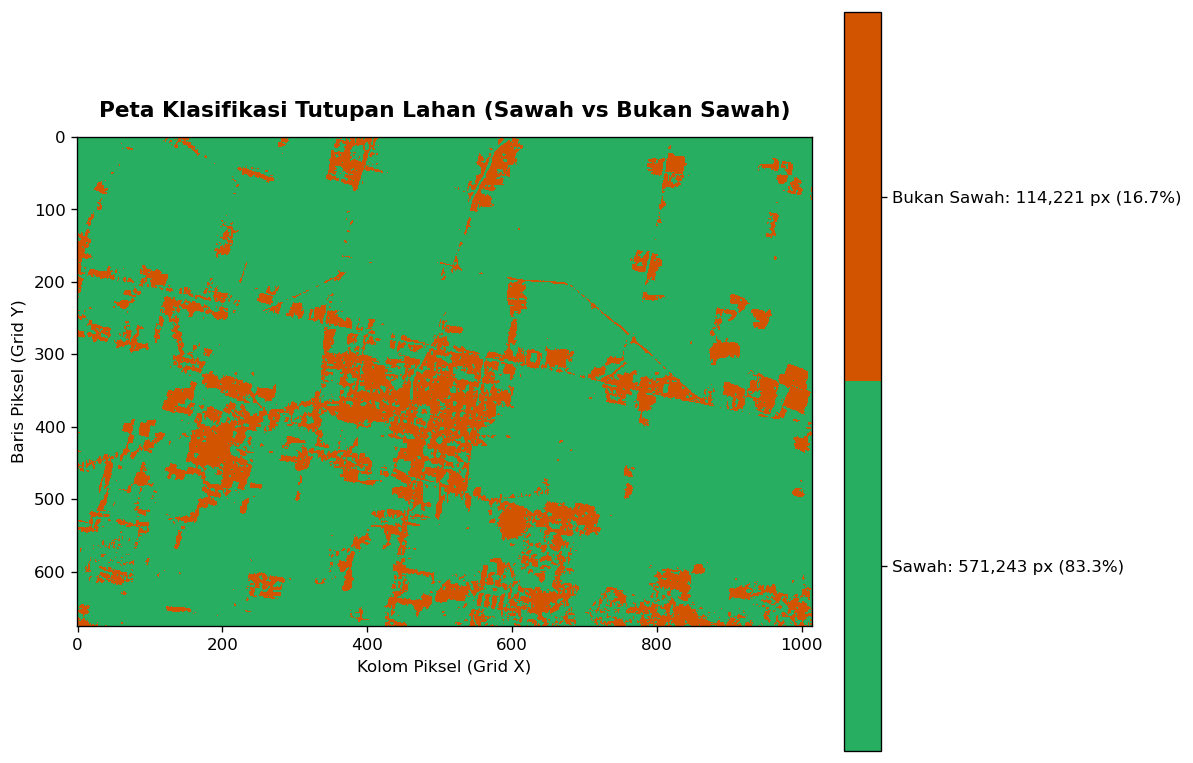


=== VISUALISASI PETA 3D INTERAKTIF (Plotly) ===
[INFO]: File 'dem_area_studi.tif' tidak ditemukan. Menggunakan proyeksi elevasi grid standar.
SUCCESS: File HTML interaktif disimpan di '../assets/editor/html/peta_3d.html'


In [4]:
import os, rasterio, numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import plotly.graph_objects as go
from rasterio.warp import reproject, Resampling

ref_tif = "../data/tif/klasifikasi_sawah_pemukiman.tif"
dem_tif = "../data/tif/dem_area_studi.tif"
html_path = "../assets/editor/html/peta_3d.html"
os.makedirs("../assets/editor/html", exist_ok=True)

if os.path.exists(ref_tif):
    with rasterio.open(ref_tif) as src:
        peta = src.read(1).astype("float32")
        res = src.res[0]
        bounds = src.bounds
        crs = src.crs

    # 1. VISUALISASI PETA 2D (Matplotlib)
    print("=== VISUALISASI PETA KLASIFIKASI 2D ===")
    peta_mask = np.where(peta == 0, np.nan, peta)
    
    # Hitung Statistik Jumlah & Persentase Piksel
    total_valid = np.sum(~np.isnan(peta_mask))
    sawah_count = np.sum(peta_mask == 1)
    bukan_sawah_count = np.sum(peta_mask == 2)
    
    cmap_custom = ListedColormap(["#27ae60", "#d35400"]) # Hijau = Sawah, Oranye = Bukan Sawah
    
    plt.figure(figsize=(10, 8), dpi=120)
    img_plot = plt.imshow(peta_mask, cmap=cmap_custom, vmin=1, vmax=2)
    
    # Buat Legenda
    cbar = plt.colorbar(img_plot, ticks=[1.25, 1.75], fraction=0.046, pad=0.04)
    cbar.ax.set_yticklabels([
        f"Sawah: {sawah_count:,} px ({(sawah_count/total_valid)*100:.1f}%)",
        f"Bukan Sawah: {bukan_sawah_count:,} px ({(bukan_sawah_count/total_valid)*100:.1f}%)"
    ], fontsize=10)
    
    plt.title("Peta Klasifikasi Tutupan Lahan (Sawah vs Bukan Sawah)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("Kolom Piksel (Grid X)", fontsize=10)
    plt.ylabel("Baris Piksel (Grid Y)", fontsize=10)
    plt.grid(False)
    plt.tight_layout()
    plt.show()

    # 2. VISUALISASI PETA 3D INTERAKTIF (Plotly Surface)
    print("\n=== VISUALISASI PETA 3D INTERAKTIF (Plotly) ===")
    if os.path.exists(dem_tif):
        with rasterio.open(dem_tif) as dem:
            dem_arr = np.zeros(peta.shape, dtype="float32")
            reproject(source=rasterio.band(dem, 1), destination=dem_arr,
                      dst_transform=src.transform, dst_crs=src.crs,
                      resampling=Resampling.bilinear)
    else:
        # Jika belum ada DEM, buat relief dasar
        print("[INFO]: File 'dem_area_studi.tif' tidak ditemukan. Menggunakan proyeksi elevasi grid standar.")
        dem_arr = np.ones(peta.shape, dtype="float32") * 10.0

    STEP = 2  # Downsample agar render 3D ringan dan cepat
    Z = dem_arr[::STEP, ::STEP]
    C = peta[::STEP, ::STEP]
    C[C == 0] = np.nan
    
    x = np.arange(Z.shape[1]) * res * STEP
    y = np.arange(Z.shape[0]) * res * STEP
    
    colorscale = [
        [0.0, "#27ae60"], [0.5, "#27ae60"],  # Sawah = Hijau
        [0.5, "#d35400"], [1.0, "#d35400"]   # Bukan Sawah = Oranye
    ]
    
    fig = go.Figure(go.Surface(
        x=x, y=y, z=Z, surfacecolor=C,
        colorscale=colorscale, cmin=1, cmax=2,
        colorbar=dict(
            title="Kelas Lahan",
            tickvals=[1.25, 1.75],
            ticktext=["Sawah", "Bukan Sawah"],
            len=0.6
        ),
        lighting=dict(ambient=0.7, diffuse=0.8, roughness=0.9),
    ))
    
    fig.update_layout(
        title="Peta 3D Interaktif Klasifikasi Sawah & Bukan Sawah",
        scene=dict(
            aspectmode="manual",
            aspectratio=dict(x=1, y=1, z=0.2),
            xaxis_title="Timur (m)",
            yaxis_title="Utara (m)",
            zaxis_title="Elevasi (m)"
        ),
        margin=dict(l=0, r=0, b=0, t=40),
        height=700
    )
    
    # Simpan ke HTML dan Tampilkan Langsung
    fig.write_html(html_path)
    print(f"SUCCESS: File HTML interaktif disimpan di '{html_path}'")
    fig.show()

else:
    print(f"[ERROR]: File '{ref_tif}' belum tersedia. Pastikan Cell 3 sudah dijalankan terlebih dahulu.")
